In [ ]:
!pip install torch torchvision torchsummary scikit-learn pandas matplotlib pillow

In [1]:
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms

from torch.optim import Adam
from torchsummary import summary

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

%matplotlib inline

In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"

print("Using device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Using device: cuda
GPU: Tesla T4


In [3]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
from pathlib import Path

zip_path = Path("/content/drive/MyDrive/EuroSAT.zip")

print("ZIP path:", zip_path)
print("ZIP exists:", zip_path.exists())

ZIP path: /content/drive/MyDrive/EuroSAT.zip
ZIP exists: True


In [6]:
import zipfile
from pathlib import Path

zip_path = Path("/content/drive/MyDrive/EuroSAT.zip")
extract_path = Path("/content/eurosat_data")

extract_path.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction completed!")

Extraction completed!


In [7]:
from pathlib import Path

extract_path = Path("/content/eurosat_data")

# Find the folder containing train.csv
matches = list(extract_path.rglob("train.csv"))

print("train.csv found at:", matches)

if len(matches) == 0:
    raise FileNotFoundError("train.csv was not found after extraction.")

data_folder = matches[0].parent

print("\nDataset folder:", data_folder)
print("Dataset exists:", data_folder.exists())

train.csv found at: [PosixPath('/content/eurosat_data/EuroSAT/train.csv')]

Dataset folder: /content/eurosat_data/EuroSAT
Dataset exists: True


In [8]:
for item in sorted(data_folder.iterdir()):
    print(item.name)

AnnualCrop
Forest
HerbaceousVegetation
Highway
Industrial
Pasture
PermanentCrop
Residential
River
SeaLake
label_map.json
test.csv
train.csv
validation.csv


In [9]:
# 1. LOAD THE DATASET SPLITS


# The downloaded EuroSAT version already provides separate
# CSV files for training, validation and testing.

train_df = pd.read_csv(data_folder / "train.csv")
val_df = pd.read_csv(data_folder / "validation.csv")
test_df = pd.read_csv(data_folder / "test.csv")

print("Training samples   :", len(train_df))
print("Validation samples :", len(val_df))
print("Testing samples    :", len(test_df))

print(
    "Total samples      :",
    len(train_df) + len(val_df) + len(test_df)
)

# Show first five records
display(train_df.head())


Training samples   : 18900
Validation samples : 5400
Testing samples    : 2700
Total samples      : 27000


,Unnamed: 0,Filename,Label,ClassName
0,16257,AnnualCrop/AnnualCrop_142.jpg,0,AnnualCrop
1,3297,HerbaceousVegetation/HerbaceousVegetation_2835...,2,HerbaceousVegetation
2,17881,PermanentCrop/PermanentCrop_1073.jpg,6,PermanentCrop
3,2223,Industrial/Industrial_453.jpg,4,Industrial
4,4887,HerbaceousVegetation/HerbaceousVegetation_1810...,2,HerbaceousVegetation


In [10]:

# 2. CLASS INFORMATION

# Extract each unique label/class pair and sort by numeric label.
class_info = (
    train_df[["Label", "ClassName"]]
    .drop_duplicates()
    .sort_values("Label")
)

display(class_info)

# Store class names in correct label order.
class_names = class_info["ClassName"].tolist()

num_classes = len(class_names)

print("Number of classes:", num_classes)

print("\nClasses:")
for i, class_name in enumerate(class_names):
    print(f"{i}: {class_name}")

,Label,ClassName
0,0,AnnualCrop
27,1,Forest
1,2,HerbaceousVegetation
8,3,Highway
3,4,Industrial
5,5,Pasture
2,6,PermanentCrop
13,7,Residential
21,8,River
23,9,SeaLake


Number of classes: 10

Classes:
0: AnnualCrop
1: Forest
2: HerbaceousVegetation
3: Highway
4: Industrial
5: Pasture
6: PermanentCrop
7: Residential
8: River
9: SeaLake


In [11]:

# 3. ANALYZE CLASS DISTRIBUTION

train_counts = (
    train_df["ClassName"]
    .value_counts()
    .reindex(class_names)
)

val_counts = (
    val_df["ClassName"]
    .value_counts()
    .reindex(class_names)
)

test_counts = (
    test_df["ClassName"]
    .value_counts()
    .reindex(class_names)
)

print("TRAINING SET:")
print(train_counts)

print("\nVALIDATION SET:")
print(val_counts)

print("\nTEST SET:")
print(test_counts)


# Measure imbalance in the TRAINING dataset.
imbalance_ratio = (
    train_counts.max() / train_counts.min()
)

print(
    "\nLargest / smallest training class ratio:",
    round(imbalance_ratio, 2)
)

TRAINING SET:
ClassName
AnnualCrop              2100
Forest                  2100
HerbaceousVegetation    2100
Highway                 1750
Industrial              1750
Pasture                 1400
PermanentCrop           1750
Residential             2100
River                   1750
SeaLake                 2100
Name: count, dtype: int64

VALIDATION SET:
ClassName
AnnualCrop              600
Forest                  600
HerbaceousVegetation    600
Highway                 500
Industrial              500
Pasture                 400
PermanentCrop           500
Residential             600
River                   500
SeaLake                 600
Name: count, dtype: int64

TEST SET:
ClassName
AnnualCrop              300
Forest                  300
HerbaceousVegetation    300
Highway                 250
Industrial              250
Pasture                 200
PermanentCrop           250
Residential             300
River                   250
SeaLake                 300
Name: count, dtype: int64


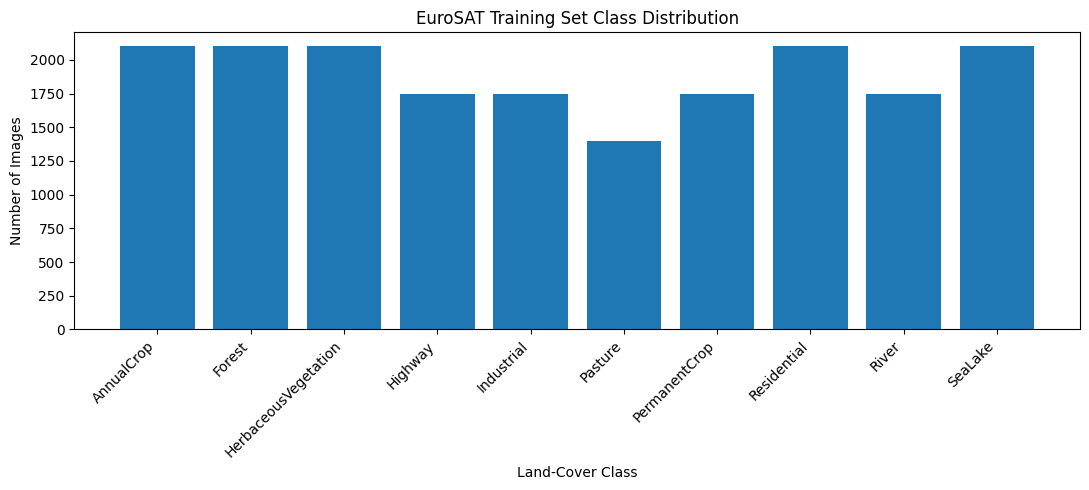

In [12]:

# 4. VISUALIZE TRAINING CLASS DISTRIBUTION

plt.figure(figsize=(11, 5))

plt.bar(
    train_counts.index,
    train_counts.values
)

plt.title("EuroSAT Training Set Class Distribution")
plt.xlabel("Land-Cover Class")
plt.ylabel("Number of Images")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [13]:

# 5. VERIFY IMAGE LOADING

sample_row = train_df.iloc[0]

sample_path = (
    data_folder / sample_row["Filename"]
)

print("Filename:", sample_row["Filename"])
print("Full path:", sample_path)
print("Image exists:", sample_path.exists())

sample_image = Image.open(
    sample_path
).convert("RGB")

print("Image size:", sample_image.size)
print("Image class:", sample_row["ClassName"])

Filename: AnnualCrop/AnnualCrop_142.jpg
Full path: /content/eurosat_data/EuroSAT/AnnualCrop/AnnualCrop_142.jpg
Image exists: True
Image size: (64, 64)
Image class: AnnualCrop


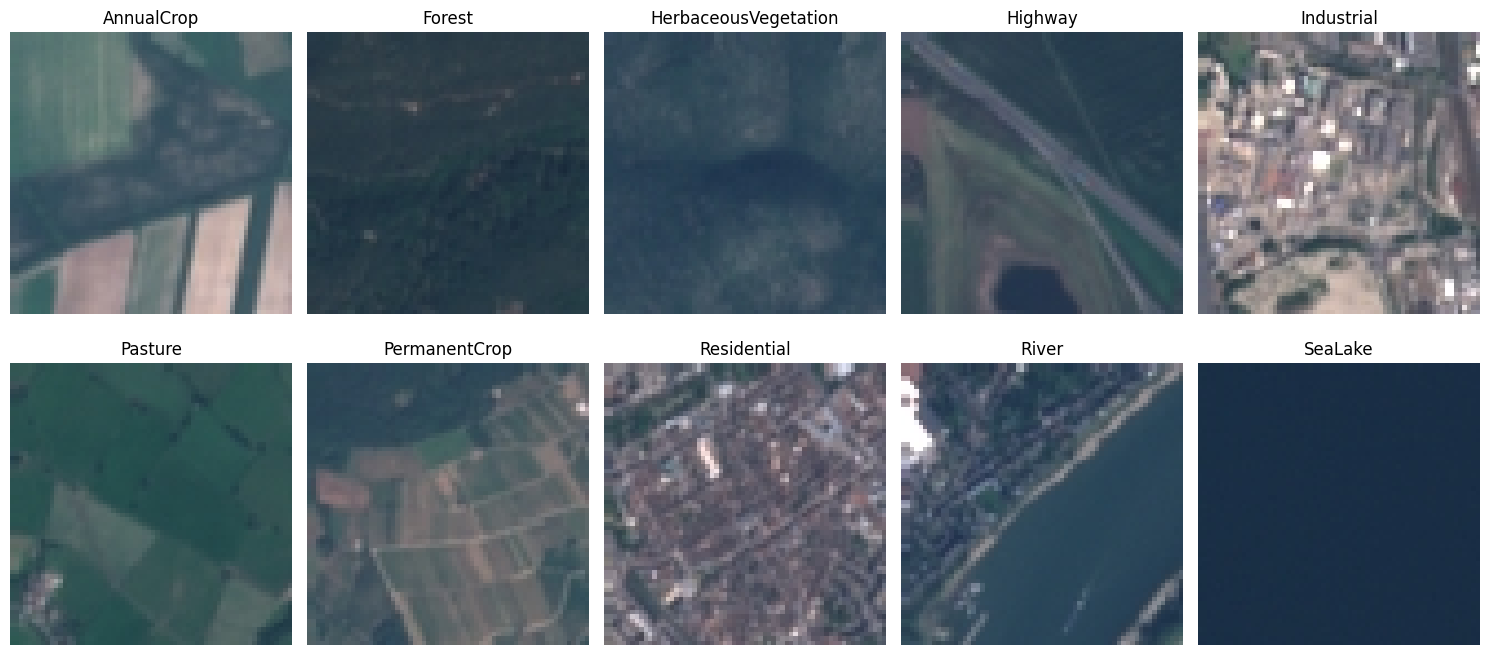

In [15]:

# 6. DISPLAY ONE IMAGE FROM EACH CLASS

plt.figure(figsize=(15, 7))

for i, class_name in enumerate(class_names):

    # Select one example belonging to this class.
    row = (
        train_df[
            train_df["ClassName"] == class_name
        ]
        .sample(1, random_state=42)
        .iloc[0]
    )

    image = Image.open(
        data_folder / row["Filename"]
    ).convert("RGB")

    plt.subplot(2, 5, i + 1)

    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [17]:

# 7.HYPERPARAMETERS

IMAGE_SIZE = 64
BATCH_SIZE = 64
LEARNING_RATE = 0.001
WEIGHT_DECAY = 1e-4
MAX_EPOCHS = 20
EARLY_STOPPING_PATIENCE = 5

print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)

Image size: 64
Batch size: 64
Learning rate: 0.001


In [18]:

# 8. IMAGE PREPROCESSING AND DATA AUGMENTATION

# Training images receive random augmentation.
train_transform = transforms.Compose([

    # Ensure all images have the expected spatial size.
    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),

    # Augmentation to improve generalization.
    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomVerticalFlip(
        p=0.5
    ),

    transforms.RandomRotation(
        degrees=15
    ),

    # Convert PIL image from [0,255] to tensor [0,1].
    transforms.ToTensor(),

    # Normalize RGB channels to approximately [-1,1].
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])


# Validation and test sets MUST NOT receive random augmentation.
eval_transform = transforms.Compose([

    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

In [19]:

# 9. CUSTOM EUROSAT DATASET CLASS

class EuroSATDataset(Dataset):

    def __init__(
        self,
        dataframe,
        root_dir,
        transform=None
    ):

        # Reset indexing to make __getitem__ reliable.
        self.dataframe = (
            dataframe
            .reset_index(drop=True)
        )

        self.root_dir = Path(root_dir)

        self.transform = transform


    def __len__(self):

        # Number of samples in the dataset.
        return len(self.dataframe)


    def __getitem__(self, index):

        # Get row corresponding to requested sample.
        row = self.dataframe.iloc[index]

        # Construct complete image path.
        image_path = (
            self.root_dir
            / row["Filename"]
        )

        # Open image and force RGB representation.
        image = Image.open(
            image_path
        ).convert("RGB")

        # Convert label to integer.
        label = int(
            row["Label"]
        )

        # Apply preprocessing/augmentation.
        if self.transform is not None:
            image = self.transform(image)

        return image, label

In [20]:

# 10. CREATE DATASETS

train_dataset = EuroSATDataset(
    dataframe=train_df,
    root_dir=data_folder,
    transform=train_transform
)

val_dataset = EuroSATDataset(
    dataframe=val_df,
    root_dir=data_folder,
    transform=eval_transform
)

test_dataset = EuroSATDataset(
    dataframe=test_df,
    root_dir=data_folder,
    transform=eval_transform
)


print(
    "Training samples:",
    len(train_dataset)
)

print(
    "Validation samples:",
    len(val_dataset)
)

print(
    "Test samples:",
    len(test_dataset)
)

Training samples: 18900
Validation samples: 5400
Test samples: 2700


In [21]:

# 11. CREATE DATALOADERS

train_loader = DataLoader(
    train_dataset,

    batch_size=BATCH_SIZE,

    # Shuffle only training data.
    shuffle=True,

    num_workers=2,

    # Improves GPU data transfer performance.
    pin_memory=(device == "cuda")
)


val_loader = DataLoader(
    val_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=2,

    pin_memory=(device == "cuda")
)


test_loader = DataLoader(
    test_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=2,

    pin_memory=(device == "cuda")
)


print(
    "Training batches:",
    len(train_loader)
)

print(
    "Validation batches:",
    len(val_loader)
)

print(
    "Testing batches:",
    len(test_loader)
)

Training batches: 296
Validation batches: 85
Testing batches: 43


In [22]:

# 12. CHECK ONE BATCH

images, labels = next(
    iter(train_loader)
)

print(
    "Image batch shape:",
    images.shape
)

print(
    "Label batch shape:",
    labels.shape
)

print(
    "Image datatype:",
    images.dtype
)

Image batch shape: torch.Size([64, 3, 64, 64])
Label batch shape: torch.Size([64])
Image datatype: torch.float32


In [23]:

# 13. CONVOLUTIONAL BLOCK

class ConvBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
        dropout_rate
    ):

        super().__init__()


        self.block = nn.Sequential(

            # First convolution.
            nn.Conv2d(
                in_channels=in_channels,
                out_channels=out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(
                out_channels
            ),

            nn.ReLU(
                inplace=True
            ),


            # Second convolution.
            nn.Conv2d(
                in_channels=out_channels,
                out_channels=out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(
                out_channels
            ),

            nn.ReLU(
                inplace=True
            ),


            # Reduce height and width by half.
            nn.MaxPool2d(
                kernel_size=2,
                stride=2
            ),


            # Spatial dropout for regularization.
            nn.Dropout2d(
                p=dropout_rate
            )
        )


    def forward(self, x):

        return self.block(x)

In [24]:

# 14. CUSTOM CNN ARCHITECTURE

class EuroSATCNN(nn.Module):

    def __init__(
        self,
        num_classes=10
    ):

        super().__init__()


        # Feature extraction section.
        self.features = nn.Sequential(

            # Input: 3 x 64 x 64
            # Output: 32 x 32 x 32
            ConvBlock(
                3,
                32,
                dropout_rate=0.05
            ),


            # Output: 64 x 16 x 16
            ConvBlock(
                32,
                64,
                dropout_rate=0.10
            ),


            # Output: 128 x 8 x 8
            ConvBlock(
                64,
                128,
                dropout_rate=0.15
            ),


            # Output: 256 x 4 x 4
            ConvBlock(
                128,
                256,
                dropout_rate=0.20
            )
        )


        # Classification section.
        self.classifier = nn.Sequential(

            # 256 * 4 * 4 = 4096 features.
            nn.Flatten(),


            nn.Linear(
                256 * 4 * 4,
                512
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.Dropout(
                p=0.50
            ),


            # Final output:
            # one score for each of 10 classes.
            nn.Linear(
                512,
                num_classes
            )
        )


    def forward(self, x):

        x = self.features(x)

        x = self.classifier(x)

        return x

In [25]:

# 15. INITIALIZE MODEL

model = EuroSATCNN(
    num_classes=num_classes
).to(device)

print(model)

EuroSATCNN(
  (features): Sequential(
    (0): ConvBlock(
      (block): Sequential(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (5): ReLU(inplace=True)
        (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
        (7): Dropout2d(p=0.05, inplace=False)
      )
    )
    (1): ConvBlock(
      (block): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1

In [26]:

# 16. MODEL ARCHITECTURE SUMMARY

from torchsummary import summary

summary(
    model,
    input_size=(3, 64, 64)
)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 32, 64, 64]             864
       BatchNorm2d-2           [-1, 32, 64, 64]              64
              ReLU-3           [-1, 32, 64, 64]               0
            Conv2d-4           [-1, 32, 64, 64]           9,216
       BatchNorm2d-5           [-1, 32, 64, 64]              64
              ReLU-6           [-1, 32, 64, 64]               0
         MaxPool2d-7           [-1, 32, 32, 32]               0
         Dropout2d-8           [-1, 32, 32, 32]               0
         ConvBlock-9           [-1, 32, 32, 32]               0
           Conv2d-10           [-1, 64, 32, 32]          18,432
      BatchNorm2d-11           [-1, 64, 32, 32]             128
             ReLU-12           [-1, 64, 32, 32]               0
           Conv2d-13           [-1, 64, 32, 32]          36,864
      BatchNorm2d-14           [-1, 64,

In [27]:

# 17. LOSS FUNCTION, OPTIMIZER AND LEARNING-RATE SCHEDULER

# Multi-class classification loss.
criterion = nn.CrossEntropyLoss()


# Adam optimizer.
optimizer = torch.optim.Adam(

    model.parameters(),

    lr=LEARNING_RATE,

    # L2-style regularization.
    weight_decay=WEIGHT_DECAY
)


# Reduce learning rate when validation loss stops improving.
scheduler = (
    torch.optim.lr_scheduler.ReduceLROnPlateau(

        optimizer,

        mode="min",

        factor=0.5,

        patience=2,

        min_lr=1e-6
    )
)

In [28]:

# 19. TRAIN FOR ONE EPOCH

def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device
):

    # Enable training behavior:
    # dropout active, BatchNorm updates statistics.
    model.train()


    running_loss = 0.0

    correct_predictions = 0

    total_samples = 0


    for images, labels in loader:

        # Transfer current batch to GPU.
        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )


        # Remove gradients from previous batch.
        optimizer.zero_grad(
            set_to_none=True
        )


        # Forward pass.
        outputs = model(images)


        # Calculate classification loss.
        loss = criterion(
            outputs,
            labels
        )


        # Calculate gradients.
        loss.backward()


        # Update network weights.
        optimizer.step()


        # Accumulate total loss.
        running_loss += (
            loss.item()
            * images.size(0)
        )


        # Predicted class = highest output score.
        predictions = outputs.argmax(
            dim=1
        )


        correct_predictions += (
            predictions == labels
        ).sum().item()


        total_samples += labels.size(0)


    epoch_loss = (
        running_loss
        / total_samples
    )


    epoch_accuracy = (
        correct_predictions
        / total_samples
    )


    return epoch_loss, epoch_accuracy

In [29]:

# 20. EVALUATION FUNCTION

@torch.no_grad()
def evaluate_model(
    model,
    loader,
    criterion,
    device
):

    # Disable training-specific behavior.
    model.eval()


    running_loss = 0.0

    correct_predictions = 0

    total_samples = 0


    for images, labels in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )


        # Forward pass only.
        outputs = model(images)


        loss = criterion(
            outputs,
            labels
        )


        running_loss += (
            loss.item()
            * images.size(0)
        )


        predictions = outputs.argmax(
            dim=1
        )


        correct_predictions += (
            predictions == labels
        ).sum().item()


        total_samples += labels.size(0)


    epoch_loss = (
        running_loss
        / total_samples
    )


    epoch_accuracy = (
        correct_predictions
        / total_samples
    )


    return epoch_loss, epoch_accuracy

In [30]:

# 21. TRAINING HISTORY AND BEST MODEL SETTINGS

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []


# Lower validation loss is considered better.
best_val_loss = float("inf")


# Number of consecutive epochs without improvement.
epochs_without_improvement = 0


# Best model will be saved here temporarily.
BEST_MODEL_PATH = (
    "/content/EuroSAT_best_model.pth"
)

In [31]:

# 22. MAIN TRAINING LOOP

for epoch in range(MAX_EPOCHS):


    # ---------------------------
    # TRAINING
    # ---------------------------

    train_loss, train_acc = train_one_epoch(

        model,
        train_loader,
        criterion,
        optimizer,
        device
    )


    # ---------------------------
    # VALIDATION
    # ---------------------------

    val_loss, val_acc = evaluate_model(

        model,
        val_loader,
        criterion,
        device
    )


    # Update scheduler based on validation loss.
    scheduler.step(val_loss)


    # Store values for graphs.
    train_losses.append(
        train_loss
    )

    train_accuracies.append(
        train_acc
    )

    val_losses.append(
        val_loss
    )

    val_accuracies.append(
        val_acc
    )


    # Get current learning rate.
    current_lr = (
        optimizer
        .param_groups[0]["lr"]
    )


    # Display epoch results.
    print(
        f"Epoch {epoch + 1:02d}/{MAX_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc * 100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc * 100:.2f}% | "
        f"LR: {current_lr:.6f}"
    )


    # ---------------------------
    # SAVE BEST MODEL
    # ---------------------------

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        epochs_without_improvement = 0


        torch.save(
            model.state_dict(),
            BEST_MODEL_PATH
        )


        print(
            "  -> Best model saved."
        )


    else:

        epochs_without_improvement += 1


    # ---------------------------
    # EARLY STOPPING
    # ---------------------------

    if (
        epochs_without_improvement
        >= EARLY_STOPPING_PATIENCE
    ):

        print(
            "\nEarly stopping activated."
        )

        break

Epoch 01/20 | Train Loss: 1.5101 | Train Acc: 45.10% | Val Loss: 1.1217 | Val Acc: 56.56% | LR: 0.001000
  -> Best model saved.
Epoch 02/20 | Train Loss: 1.0503 | Train Acc: 63.83% | Val Loss: 0.7608 | Val Acc: 73.30% | LR: 0.001000
  -> Best model saved.
Epoch 03/20 | Train Loss: 0.9138 | Train Acc: 68.85% | Val Loss: 0.7205 | Val Acc: 72.96% | LR: 0.001000
  -> Best model saved.
Epoch 04/20 | Train Loss: 0.8157 | Train Acc: 72.33% | Val Loss: 0.6390 | Val Acc: 77.06% | LR: 0.001000
  -> Best model saved.
Epoch 05/20 | Train Loss: 0.7550 | Train Acc: 74.92% | Val Loss: 0.5737 | Val Acc: 80.20% | LR: 0.001000
  -> Best model saved.
Epoch 06/20 | Train Loss: 0.7041 | Train Acc: 76.79% | Val Loss: 0.5945 | Val Acc: 79.31% | LR: 0.001000
Epoch 07/20 | Train Loss: 0.6679 | Train Acc: 78.12% | Val Loss: 0.4396 | Val Acc: 85.87% | LR: 0.001000
  -> Best model saved.
Epoch 08/20 | Train Loss: 0.6263 | Train Acc: 79.97% | Val Loss: 0.4672 | Val Acc: 83.61% | LR: 0.001000
Epoch 09/20 | Train Lo

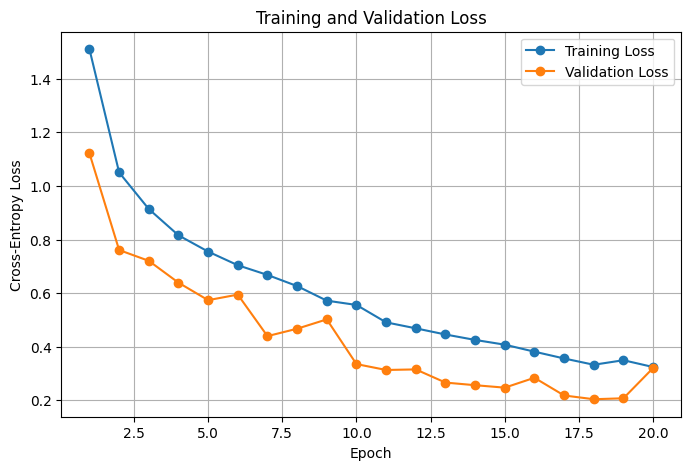

In [32]:

# 23. TRAINING AND VALIDATION LOSS CURVES
# ============================================================

epochs_completed = range(
    1,
    len(train_losses) + 1
)


plt.figure(figsize=(8, 5))


plt.plot(
    epochs_completed,
    train_losses,
    marker="o",
    label="Training Loss"
)


plt.plot(
    epochs_completed,
    val_losses,
    marker="o",
    label="Validation Loss"
)


plt.title(
    "Training and Validation Loss"
)

plt.xlabel("Epoch")

plt.ylabel("Cross-Entropy Loss")

plt.legend()

plt.grid()

plt.show()

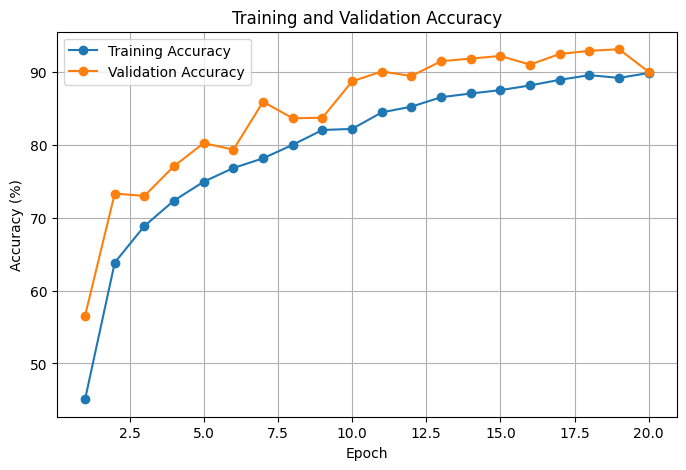

In [33]:

# 24. TRAINING AND VALIDATION ACCURACY CURVES

plt.figure(figsize=(8, 5))


plt.plot(
    epochs_completed,
    np.array(train_accuracies) * 100,
    marker="o",
    label="Training Accuracy"
)


plt.plot(
    epochs_completed,
    np.array(val_accuracies) * 100,
    marker="o",
    label="Validation Accuracy"
)


plt.title(
    "Training and Validation Accuracy"
)

plt.xlabel("Epoch")

plt.ylabel("Accuracy (%)")

plt.legend()

plt.grid()

plt.show()

In [34]:

# 25. LOAD THE BEST VALIDATION MODEL
model.load_state_dict(

    torch.load(
        BEST_MODEL_PATH,
        map_location=device
    )
)


model = model.to(device)


print(
    "Best validation model loaded successfully."
)

Best validation model loaded successfully.


In [35]:

# 26. FINAL TEST EVALUATION

test_loss, test_accuracy = evaluate_model(

    model,
    test_loader,
    criterion,
    device
)


print(
    f"Test Loss     : {test_loss:.4f}"
)


print(
    f"Test Accuracy : "
    f"{test_accuracy * 100:.2f}%"
)

Test Loss     : 0.1836
Test Accuracy : 94.33%


In [36]:

# 27. COLLECT TEST PREDICTIONS

all_true_labels = []

all_predictions = []

all_probabilities = []


model.eval()


with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)


        # Model output logits.
        outputs = model(images)


        # Convert logits into probabilities.
        probabilities = torch.softmax(
            outputs,
            dim=1
        )


        # Select class with highest probability.
        predictions = probabilities.argmax(
            dim=1
        )


        all_true_labels.extend(
            labels.numpy()
        )


        all_predictions.extend(
            predictions.cpu().numpy()
        )


        all_probabilities.extend(
            probabilities.cpu().numpy()
        )


all_true_labels = np.array(
    all_true_labels
)

all_predictions = np.array(
    all_predictions
)

all_probabilities = np.array(
    all_probabilities
)


print(
    "Predictions collected:",
    len(all_predictions)
)

Predictions collected: 2700


In [37]:

# 28. COMPREHENSIVE TEST METRICS

overall_accuracy = accuracy_score(
    all_true_labels,
    all_predictions
)


weighted_precision = precision_score(
    all_true_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)


weighted_recall = recall_score(
    all_true_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)


weighted_f1 = f1_score(
    all_true_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)


macro_precision = precision_score(
    all_true_labels,
    all_predictions,
    average="macro",
    zero_division=0
)


macro_recall = recall_score(
    all_true_labels,
    all_predictions,
    average="macro",
    zero_division=0
)


macro_f1 = f1_score(
    all_true_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

In [38]:
print(
    f"Test Accuracy       : "
    f"{overall_accuracy * 100:.2f}%"
)

print(
    f"Weighted Precision  : "
    f"{weighted_precision:.4f}"
)

print(
    f"Weighted Recall     : "
    f"{weighted_recall:.4f}"
)

print(
    f"Weighted F1 Score   : "
    f"{weighted_f1:.4f}"
)

print()

print(
    f"Macro Precision     : "
    f"{macro_precision:.4f}"
)

print(
    f"Macro Recall        : "
    f"{macro_recall:.4f}"
)

print(
    f"Macro F1 Score      : "
    f"{macro_f1:.4f}"
)

Test Accuracy       : 94.33%
Weighted Precision  : 0.9446
Weighted Recall     : 0.9433
Weighted F1 Score   : 0.9435

Macro Precision     : 0.9427
Macro Recall        : 0.9425
Macro F1 Score      : 0.9422


In [39]:

# 29. PER-CLASS CLASSIFICATION REPORT

report = classification_report(

    all_true_labels,

    all_predictions,

    labels=list(
        range(num_classes)
    ),

    target_names=class_names,

    digits=4,

    zero_division=0
)


print(report)

                      precision    recall  f1-score   support

          AnnualCrop     0.9681    0.9100    0.9381       300
              Forest     0.9857    0.9200    0.9517       300
HerbaceousVegetation     0.8842    0.9167    0.9002       300
             Highway     0.9316    0.9800    0.9552       250
          Industrial     0.9876    0.9520    0.9695       250
             Pasture     0.9200    0.9200    0.9200       200
       PermanentCrop     0.8621    0.9000    0.8806       250
         Residential     0.9967    0.9933    0.9950       300
               River     0.9325    0.9400    0.9363       250
             SeaLake     0.9582    0.9933    0.9755       300

            accuracy                         0.9433      2700
           macro avg     0.9427    0.9425    0.9422      2700
        weighted avg     0.9446    0.9433    0.9435      2700



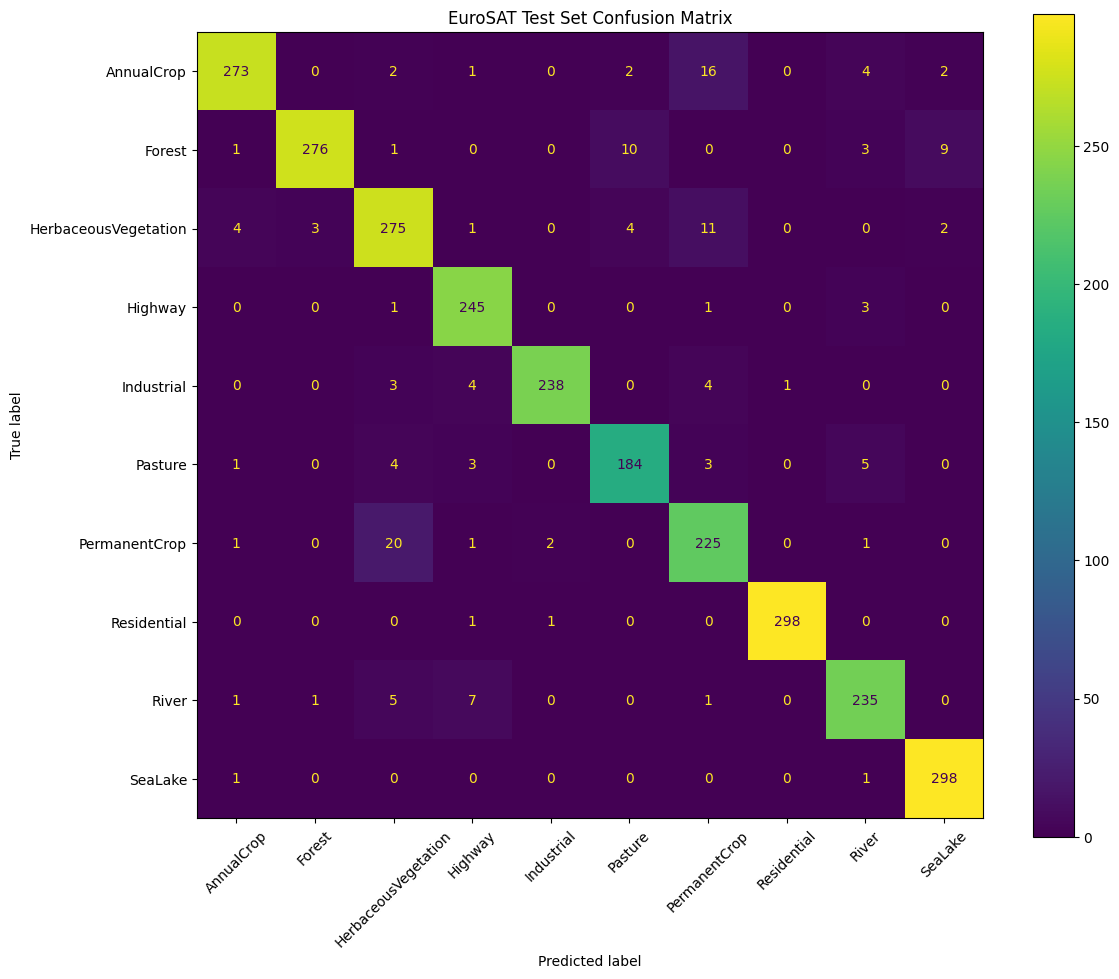

In [40]:

# 30. CONFUSION MATRIX

cm = confusion_matrix(

    all_true_labels,

    all_predictions,

    labels=list(
        range(num_classes)
    )
)


fig, ax = plt.subplots(
    figsize=(12, 10)
)


disp = ConfusionMatrixDisplay(

    confusion_matrix=cm,

    display_labels=class_names
)


disp.plot(

    ax=ax,

    xticks_rotation=45,

    values_format="d"
)


plt.title(
    "EuroSAT Test Set Confusion Matrix"
)

plt.tight_layout()

plt.show()

In [41]:

# 31. PER-CLASS PERFORMANCE TABLE

report_dict = classification_report(

    all_true_labels,

    all_predictions,

    labels=list(
        range(num_classes)
    ),

    target_names=class_names,

    output_dict=True,

    zero_division=0
)


metrics_df = pd.DataFrame(
    report_dict
).transpose()


per_class_metrics = metrics_df.loc[

    class_names,

    [
        "precision",
        "recall",
        "f1-score",
        "support"
    ]
]


display(
    per_class_metrics.round(4)
)

,precision,recall,f1-score,support
AnnualCrop,0.9681,0.9100,0.9381,300.0
Forest,0.9857,0.9200,0.9517,300.0
HerbaceousVegetation,0.8842,0.9167,0.9002,300.0
Highway,0.9316,0.9800,0.9552,250.0
Industrial,0.9876,0.9520,0.9695,250.0
Pasture,0.9200,0.9200,0.9200,200.0
PermanentCrop,0.8621,0.9000,0.8806,250.0
Residential,0.9967,0.9933,0.9950,300.0
River,0.9325,0.9400,0.9363,250.0
SeaLake,0.9582,0.9933,0.9755,300.0


In [42]:

# 32. BEST AND WORST PERFORMING CLASSES

best_class = (
    per_class_metrics[
        "f1-score"
    ]
    .idxmax()
)


worst_class = (
    per_class_metrics[
        "f1-score"
    ]
    .idxmin()
)


best_f1 = (
    per_class_metrics.loc[
        best_class,
        "f1-score"
    ]
)


worst_f1 = (
    per_class_metrics.loc[
        worst_class,
        "f1-score"
    ]
)


print(
    f"Best performing class: "
    f"{best_class}"
)

print(
    f"Best F1 score: "
    f"{best_f1:.4f}"
)


print()


print(
    f"Worst performing class: "
    f"{worst_class}"
)

print(
    f"Worst F1 score: "
    f"{worst_f1:.4f}"
)

Best performing class: Residential
Best F1 score: 0.9950

Worst performing class: PermanentCrop
Worst F1 score: 0.8806


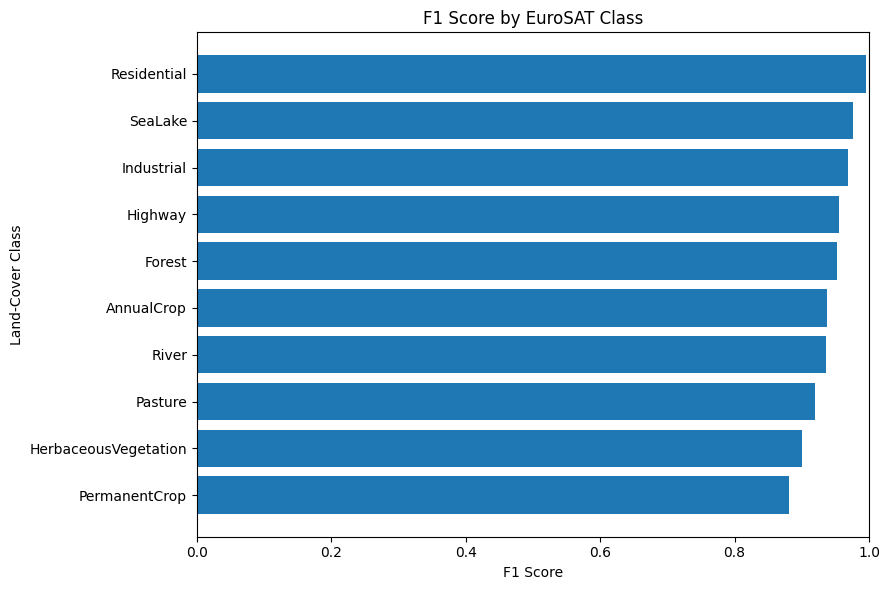

In [43]:

# 33. VISUALIZE CLASS-WISE F1 SCORE
# ============================================================

sorted_f1 = (
    per_class_metrics[
        "f1-score"
    ]
    .sort_values()
)


plt.figure(
    figsize=(9, 6)
)


plt.barh(
    sorted_f1.index,
    sorted_f1.values
)


plt.title(
    "F1 Score by EuroSAT Class"
)

plt.xlabel(
    "F1 Score"
)

plt.ylabel(
    "Land-Cover Class"
)

plt.xlim(
    0,
    1
)

plt.tight_layout()

plt.show()

In [44]:

# 34. MOST COMMON MISCLASSIFICATION

# Copy confusion matrix so original remains unchanged.
cm_errors = cm.copy()


# Remove correct predictions from consideration.
np.fill_diagonal(
    cm_errors,
    0
)


# Find location of largest off-diagonal value.
true_index, predicted_index = (
    np.unravel_index(
        np.argmax(cm_errors),
        cm_errors.shape
    )
)


most_confused_count = (
    cm_errors[
        true_index,
        predicted_index
    ]
)


print(
    "Most frequent confusion:"
)

print(
    f"True class     : "
    f"{class_names[true_index]}"
)

print(
    f"Predicted as   : "
    f"{class_names[predicted_index]}"
)

print(
    f"Number of cases: "
    f"{most_confused_count}"
)

Most frequent confusion:
True class     : PermanentCrop
Predicted as   : HerbaceousVegetation
Number of cases: 20


In [45]:

# 35. DISPLAY EXAMPLE TEST PREDICTIONS

images, labels = next(
    iter(test_loader)
)


images_gpu = images.to(
    device
)


model.eval()


with torch.no_grad():

    outputs = model(
        images_gpu
    )


    probabilities = torch.softmax(
        outputs,
        dim=1
    )


    predictions = probabilities.argmax(
        dim=1
    ).cpu()


    confidences = probabilities.max(
        dim=1
    ).values.cpu()

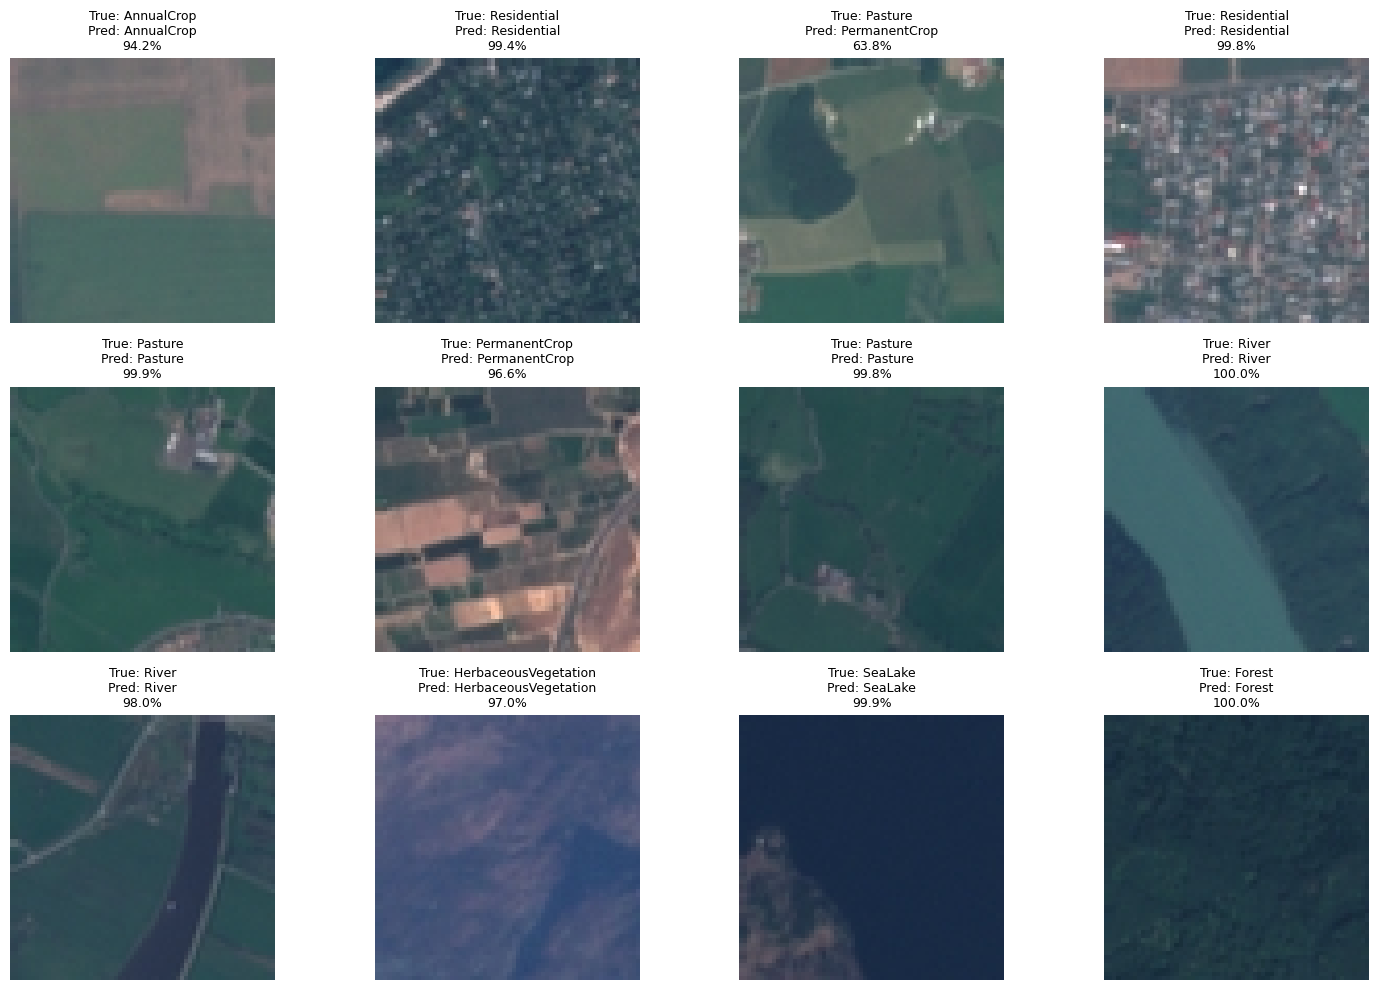

In [46]:
plt.figure(
    figsize=(15, 10)
)


for i in range(12):


    # Reverse normalization:
    # x_normalized = (x - 0.5)/0.5
    image = (
        images[i]
        * 0.5
        + 0.5
    )


    image = (
        image
        .permute(1, 2, 0)
        .numpy()
    )


    image = np.clip(
        image,
        0,
        1
    )


    true_name = class_names[
        labels[i].item()
    ]


    predicted_name = class_names[
        predictions[i].item()
    ]


    confidence = (
        confidences[i].item()
        * 100
    )


    plt.subplot(
        3,
        4,
        i + 1
    )


    plt.imshow(image)


    plt.title(
        f"True: {true_name}\n"
        f"Pred: {predicted_name}\n"
        f"{confidence:.1f}%",
        fontsize=9
    )


    plt.axis("off")


plt.tight_layout()

plt.show()

In [47]:

# 36. SAVE FINAL TRAINED MODEL WEIGHTS

FINAL_MODEL_PATH = (
    "/content/EuroSAT_CustomCNN_weights.pth"
)


torch.save(
    model.state_dict(),
    FINAL_MODEL_PATH
)


print(
    "Model saved to:",
    FINAL_MODEL_PATH
)

Model saved to: /content/EuroSAT_CustomCNN_weights.pth


In [48]:
model_size_mb = (

    os.path.getsize(
        FINAL_MODEL_PATH
    )

    / (1024 ** 2)
)


print(
    f"Model size: "
    f"{model_size_mb:.2f} MB"
)

Model size: 12.52 MB


In [49]:

# 37. SAVE ASSIGNMENT OUTPUTS PERMANENTLY TO GOOGLE DRIVE

import shutil


assignment_folder = Path(

    "/content/drive/MyDrive/"
    "EuroSAT_CNN_Assignment"

)


assignment_folder.mkdir(

    parents=True,

    exist_ok=True
)


# Copy trained model weights.
shutil.copy(

    FINAL_MODEL_PATH,

    assignment_folder
)


print(
    "Model copied to:",
    assignment_folder
)

Model copied to: /content/drive/MyDrive/EuroSAT_CNN_Assignment


In [50]:

# 38. SAVE PERFORMANCE RESULTS

overall_results = pd.DataFrame({

    "Metric": [

        "Test Accuracy",

        "Weighted Precision",

        "Weighted Recall",

        "Weighted F1",

        "Macro Precision",

        "Macro Recall",

        "Macro F1"

    ],

    "Value": [

        overall_accuracy,

        weighted_precision,

        weighted_recall,

        weighted_f1,

        macro_precision,

        macro_recall,

        macro_f1
    ]
})


display(
    overall_results.round(4)
)

,Metric,Value
0,Test Accuracy,0.9433
1,Weighted Precision,0.9446
2,Weighted Recall,0.9433
3,Weighted F1,0.9435
4,Macro Precision,0.9427
5,Macro Recall,0.9425
6,Macro F1,0.9422


In [51]:
overall_results.to_csv(

    assignment_folder
    / "overall_results.csv",

    index=False
)


per_class_metrics.to_csv(

    assignment_folder
    / "per_class_results.csv"
)


print(
    "Results saved successfully."
)

Results saved successfully.


In [ ]:
#Analysis & Discussion
The model achieved 94.33% test accuracy.
Training and validation accuracy increased steadily throughout training.
Validation loss decreased until the best epoch, showing effective learning.
Regularization techniques such as data augmentation, dropout, batch normalization, weight decay, and early stopping helped reduce overfitting.
The best-performing class was Residential with an F1-score of 0.9950.
The worst-performing class was PermanentCrop with an F1-score of 0.8806.
The most common confusion occurred between PermanentCrop and HerbaceousVegetation, likely because these land-cover types have similar visual patterns in satellite imagery

In [ ]:
#Conclusion & Future Work
#Conclusion
In this assignment, a custom Convolutional Neural Network (CNN) was developed to classify satellite images from the EuroSAT dataset into ten different land-cover classes.
The model was trained using the Adam optimizer and Cross-Entropy Loss, while techniques such as data augmentation, batch normalization, dropout, weight decay, learning rate scheduling, and early stopping were applied to improve generalization and reduce overfitting.
The trained model achieved a test accuracy of 94.33%, demonstrating strong classification performance. In addition, the evaluation using Precision, Recall, F1-score, and the Confusion Matrix showed that the model performed well across most classes.
The best-performing class achieved an F1-score close to 1.0, while the worst-performing class mainly experienced confusion with visually similar land-cover categories.
Overall, the proposed CNN successfully learned meaningful image features and produced reliable classification results on unseen test data.

#Future Work
Transfer Learning: Compare the custom CNN with pre-trained models such as ResNet-50, EfficientNet, or DenseNet to improve classification accuracy and reduce training time.
Hyperparameter Optimization: Experiment with different learning rates, batch sizes, optimizers, kernel sizes, and dropout rates to determine the optimal model configuration.
Advanced Data Augmentation: Apply more sophisticated augmentation techniques such as Color Jitter, Random Crop, Random Erasing, MixUp, or CutMix to further improve model robustness.
Attention Mechanisms: Integrate attention modules such as Squeeze-and-Excitation (SE) or CBAM to help the model focus on the most informative regions of satellite images.
Explainable AI (XAI): Use visualization techniques such as Grad-CAM or Class Activation Maps (CAM) to understand which image regions contribute most to the model's predictions and improve interpretability.
Real-Time Deployment: Deploy the trained model as a simple web application or API that can classify newly uploaded satellite images for practical use.
Evaluation on Larger Datasets: Test the model on larger and more diverse remote sensing datasets to evaluate its scalability and generalization ability.
Class Imbalance Handling: For future datasets with significant class imbalance, explore methods such as Weighted Cross-Entropy Loss, WeightedRandomSampler, or class-specific data augmentation to improve performance on minority classes.